In [2]:
import pandas as pd
from tsfresh import extract_features
from tsfresh.feature_extraction import EfficientFCParameters
import hdbscan
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import umap
import random
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [3]:
df_train = pd.read_parquet('../data/raw/X_train.parquet').reset_index()
df_train

,id,time,value,period
0,0,0,-0.005564,0
1,0,1,0.003705,0
2,0,2,0.013164,0
3,0,3,0.007151,0
4,0,4,-0.009979,0
...,...,...,...,...
23715729,10000,2134,0.001137,1
23715730,10000,2135,0.003526,1
23715731,10000,2136,0.000687,1
23715732,10000,2137,0.001640,1


In [4]:
y_train = pd.read_parquet('../data/raw/y_train.parquet')
y_train

,structural_breakpoint
id,
0,False
1,False
2,True
3,False
4,False
...,...
9996,False
9997,False
9998,False


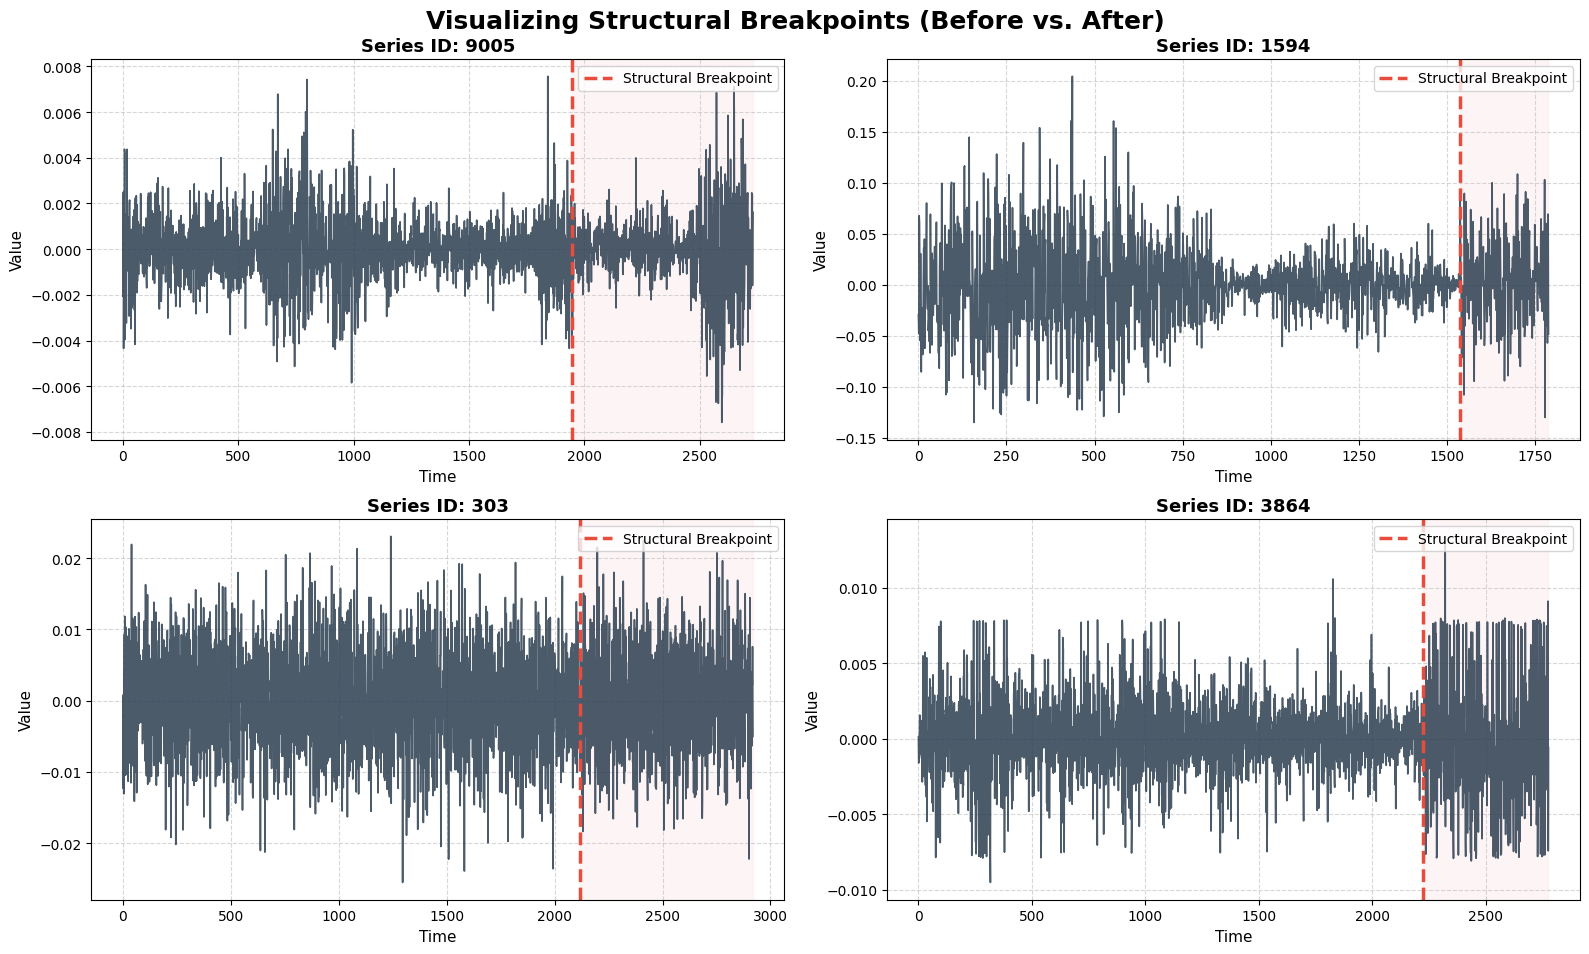

In [ ]:
# 1. Filter IDs that actually HAVE a structural breakpoint
break_ids = y_train[y_train['structural_breakpoint'] == 1].index.tolist()

# 2. Select 4 random IDs to plot
random.seed(42) 
sample_ids = random.sample(break_ids, 4)

# 3. Setup the canvas (2x2 grid)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
fig.suptitle("Visualizing Structural Breakpoints (Before vs. After)", 
             fontsize=18, fontweight='bold', y=0.95)

# 4. Plot each series
for i, seq_id in enumerate(sample_ids):
    # Determine the subplot position (row and column)
    row = i // 2
    col = i % 2
    ax = axes[row, col]
    
    # Filter the raw data for this specific ID and sort by time
    series_data = df_train[df_train['id'] == seq_id].sort_values('time')
    
    # Find the exact timestamp where the period changes from 0 to 1
    post_data = series_data[series_data['period'] == 1]
    
    # Plot the full time series
    ax.plot(series_data['time'], series_data['value'], color='#2c3e50', linewidth=1.2, alpha=0.85)
    
    # Draw the Red Vertical Line for the Breakpoint
    if not post_data.empty:
        break_time = post_data['time'].iloc[0]
        ax.axvline(x=break_time, color='#e74c3c', linestyle='--', linewidth=2.5, 
                   label='Structural Breakpoint')
        
        # Shade the 'Post' period background slightly red for visual clarity
        ax.axvspan(break_time, series_data['time'].max(), color='#e74c3c', alpha=0.05)
        
    # Aesthetics
    ax.set_title(f"Series ID: {seq_id}", fontsize=13, fontweight='bold')
    ax.set_xlabel("Time", fontsize=11)
    ax.set_ylabel("Value", fontsize=11)
    ax.legend(loc="upper right")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.subplots_adjust(top=0.90) # Leave room for the main title
plt.show()

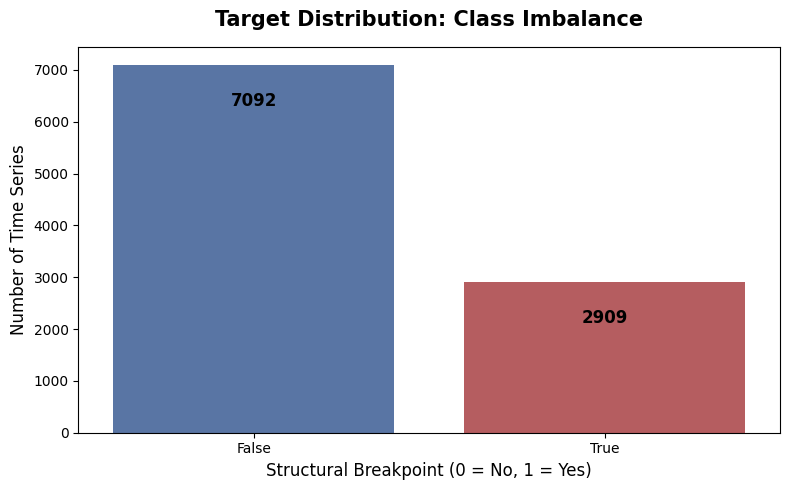

In [10]:
plt.figure(figsize=(8, 5))
# Use countplot to create the bar chart
ax = sns.countplot(data=y_train, x='structural_breakpoint', palette=['#4C72B0', '#C44E52'])

plt.title('Target Distribution: Class Imbalance', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Structural Breakpoint (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Number of Time Series', fontsize=12)

# Add the exact number above each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height() - 1000), 
                ha='center', va='bottom', 
                fontsize=12, fontweight='bold', color='black', xytext=(0, 5), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

In [20]:
df_train_pre = df_train[df_train['period'] == 0][['id', 'time', 'value']]

features_pre = extract_features(df_train_pre,
                                  column_id='id',
                                  column_sort='time',
                                  default_fc_parameters=EfficientFCParameters())

features_pre

Feature Extraction: 100%|██████████| 30/30 [15:29<00:00, 30.97s/it]  


,value__variance_larger_than_standard_deviation,value__has_duplicate_max,value__has_duplicate_min,value__has_duplicate,value__sum_values,value__abs_energy,value__mean_abs_change,value__mean_change,value__mean_second_derivative_central,value__median,...,value__fourier_entropy__bins_5,value__fourier_entropy__bins_10,value__fourier_entropy__bins_100,value__permutation_entropy__dimension_3__tau_1,value__permutation_entropy__dimension_4__tau_1,value__permutation_entropy__dimension_5__tau_1,value__permutation_entropy__dimension_6__tau_1,value__permutation_entropy__dimension_7__tau_1,value__query_similarity_count__query_None__threshold_0.0,value__mean_n_absolute_max__number_of_maxima_7
0,0.0,0.0,0.0,0.0,0.019710,0.065914,0.008448,9.075709e-06,-4.536086e-06,0.000210,...,1.251380,1.899685,3.901659,1.791471,3.173430,4.747361,6.287512,7.048998,NaN,0.022439
1,0.0,0.0,0.0,0.0,0.288593,0.014351,0.002472,3.788110e-07,-8.309391e-08,0.000123,...,1.339800,1.948612,3.875659,1.790908,3.171227,4.756078,6.403575,7.428179,NaN,0.015004
2,0.0,0.0,0.0,0.0,0.908016,0.691967,0.018782,1.199600e-05,5.831281e-07,0.000677,...,1.061457,1.613523,3.632288,1.791397,3.173513,4.764133,6.425675,7.469228,NaN,0.080921
3,0.0,0.0,0.0,0.0,0.865901,0.160037,0.008821,5.243518e-06,-5.256347e-06,0.000271,...,1.231064,1.904570,3.889163,1.789475,3.169980,4.756812,6.397927,7.443334,NaN,0.044185
4,0.0,0.0,0.0,0.0,-0.026450,0.018182,0.002530,-1.875730e-06,3.244299e-07,0.000022,...,0.972701,1.566108,3.392204,1.775852,3.118779,4.621829,6.108412,7.022356,NaN,0.009592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,0.0,0.0,0.0,0.0,0.326117,0.128646,0.007634,-1.022043e-05,3.264992e-06,-0.001153,...,1.246680,1.870481,3.884773,1.791188,3.166847,4.731330,6.345767,7.383472,NaN,0.050583
9997,0.0,0.0,0.0,0.0,0.270358,0.066001,0.006869,1.757713e-06,2.945528e-06,0.000180,...,1.280908,1.936087,3.858898,1.790951,3.172606,4.753579,6.349743,7.261048,NaN,0.018950
9998,0.0,0.0,0.0,0.0,-0.017695,0.131916,0.008953,-2.185868e-06,-1.395397e-06,0.000018,...,1.279643,1.915858,3.893771,1.791366,3.174699,4.765067,6.412818,7.506163,NaN,0.023807
9999,0.0,0.0,0.0,0.0,0.139780,0.002491,0.001215,2.148256e-07,6.109564e-08,0.000062,...,1.177818,1.851614,3.861134,1.790616,3.173709,4.761597,6.393425,7.365158,NaN,0.006431


In [21]:
features_pre.isna().sum()[features_pre.isna().sum() > 0]

value__query_similarity_count__query_None__threshold_0.0    10001
dtype: int64

In [22]:
features_pre_clean = features_pre.dropna(axis=1, how='all').copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_pre_clean)

In [23]:
print("\n--- Training UMAP & HDBSCAN with optimal parameters ---")

# 1. Reduce using UMAP for clustering
reducer = umap.UMAP(n_neighbors=30, 
                        n_components=15, 
                        min_dist=0.0, 
                        metric='cosine',
                        random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# 2. Apply HDBSCAN
clusterer = hdbscan.HDBSCAN(min_cluster_size=40, 
                            min_samples=5, 
                            metric='euclidean',
                            gen_min_span_tree=True)

cluster_labels = clusterer.fit_predict(X_umap)

# 3. Evaluate and print metrics
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)
noise_percentage = (n_noise / len(cluster_labels)) * 100

print(f"Clusters Found: {n_clusters}")
print(f"Noise: {noise_percentage:.2f}%")

if n_clusters > 1:
    dbcv_score = clusterer.relative_validity_
    print(f"DBCV Score: {dbcv_score:.4f}")
else:
    print("DBCV Score: N/A (More than 1 cluster needed)")


--- Training UMAP & HDBSCAN with optimal parameters ---
Clusters Found: 6
Noise: 0.30%
DBCV Score: 0.6940


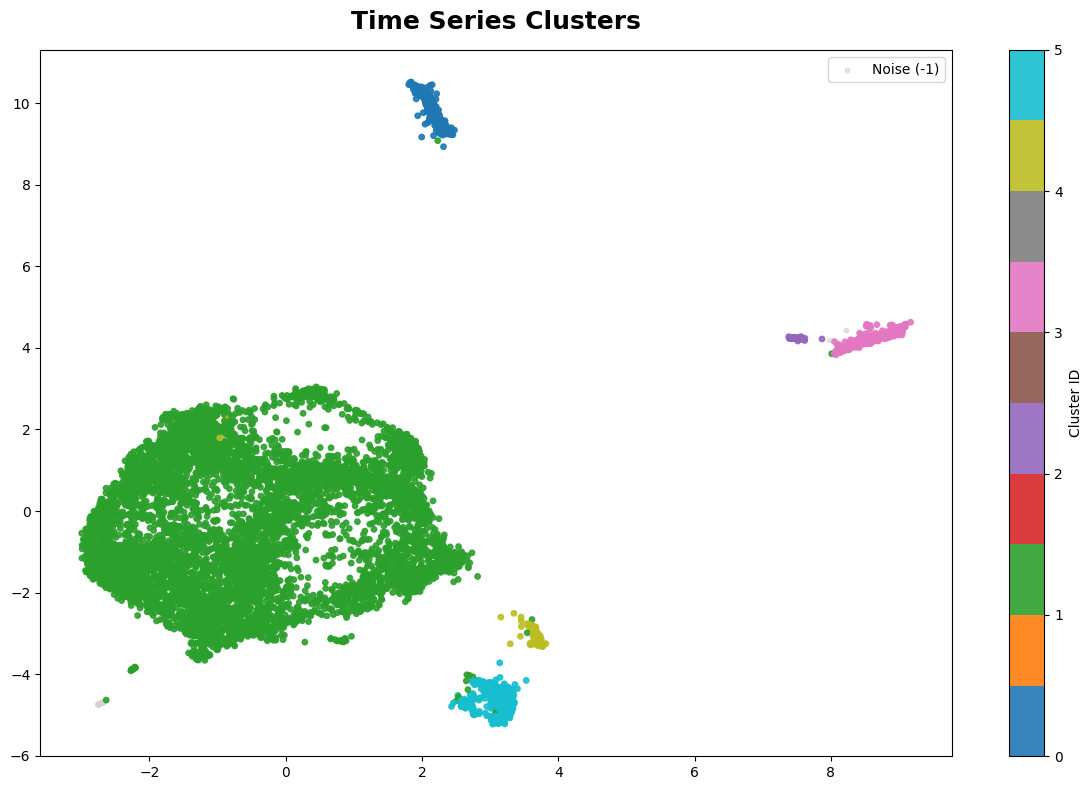

In [24]:
# Reduce to 2 dimensions only to graph
reducer_2d = umap.UMAP(n_neighbors=30, 
                       n_components=2, 
                       min_dist=0.0, 
                       metric='cosine',
                       random_state=42)

X_umap_2d = reducer_2d.fit_transform(X_scaled)

# ---------------- GRAPH ----------------
plt.figure(figsize=(12, 8))

noise = cluster_labels == -1
plt.scatter(X_umap_2d[noise, 0], X_umap_2d[noise, 1], 
            color='lightgrey', s=10, label='Noise (-1)', alpha=0.6)

valids = cluster_labels != -1
scatter = plt.scatter(X_umap_2d[valids, 0], X_umap_2d[valids, 1], 
                      c=cluster_labels[valids], cmap='tab10', s=15, alpha=0.9)

plt.title("Time Series Clusters", fontsize=18, fontweight='bold', pad=15)
plt.colorbar(scatter, label="Cluster ID")
plt.legend()
plt.tight_layout()
plt.show()

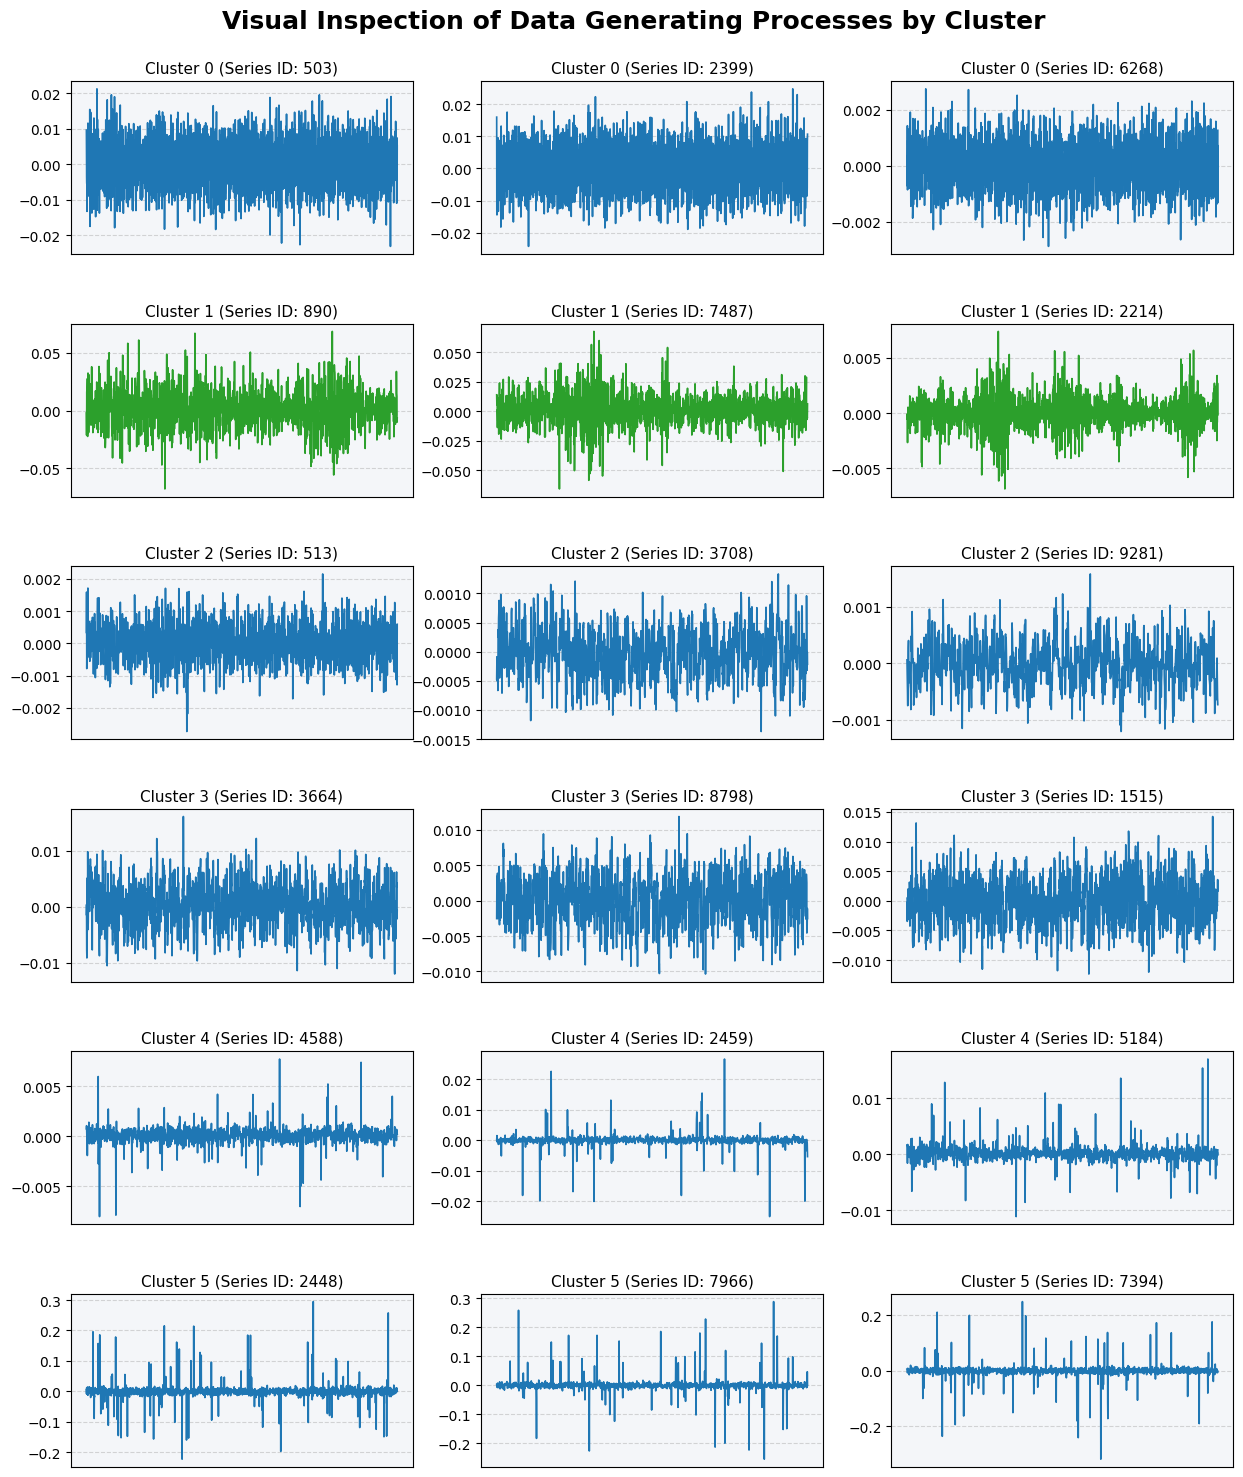

In [25]:
# Save the results of the last trained model
features_pre_clean['Cluster_ID'] = cluster_labels

# Get the IDs of valid clusters (ignoring noise -1 if present)
unique_clusters = sorted([c for c in features_pre_clean['Cluster_ID'].unique() if c != -1])

# ---------------- GRAPH ----------------
fig, axes = plt.subplots(nrows=len(unique_clusters), ncols=3, figsize=(15, 3 * len(unique_clusters)))
fig.subplots_adjust(hspace=0.4)
fig.suptitle("Visual Inspection of Data Generating Processes by Cluster", 
             fontsize=18, fontweight='bold', y=0.92)

for i, cluster in enumerate(unique_clusters):
    # Find all 'id's of the series belonging to this cluster
    ids_in_cluster = features_pre_clean[features_pre_clean['Cluster_ID'] == cluster].index.tolist()
    
    # Choose 3 random IDs
    sample_ids = random.sample(ids_in_cluster, min(3, len(ids_in_cluster)))
    
    for j, series_id in enumerate(sample_ids):
        # Filter the raw data for this specific series
        series_data = df_train_pre[df_train_pre['id'] == series_id]
        
        # Select the corresponding subplot
        if len(unique_clusters) > 1:
            ax = axes[i, j]
        else:
            ax = axes[j]
            
        # Draw the time series line
        ax.plot(series_data['time'], series_data['value'], color='#2ca02c' if cluster==1 else '#1f77b4', linewidth=1.2)
        
        # Titles and aesthetics
        ax.set_title(f"Cluster {cluster} (Series ID: {series_id})", fontsize=11)
        ax.set_xticks([])
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.set_facecolor('#f4f6f9')

plt.show()

In [26]:
df_clusters = features_pre_clean[['Cluster_ID']].reset_index()
df_clusters.rename(columns={'index': 'id'}, inplace=True)

save_path = '../data/processed/cluster_labels.parquet'
df_clusters.to_parquet(save_path, index=False)